# Twisted SrTiO$_3$ membranes

> Georgios Varnavides | Oct 8 2026
>
> Sample: two 2-unit-cell [001] SrTiO$_3$ films twisted by 36.87 deg, a single film, and a 78 A crystal
> Sampling conditions: 0.2 A step-size (Nyquist for the 25 mrad bright field)
> Imaging conditions: 300 kV, 25 mrad, 100 A underfocus at each specimen's mid-plane
> Partial coherence: 50 A focal spread and a 0.25 A source for the film, 20 A focal spread for the bilayer

These datasets are used by the direct ptychography tutorials on kernels, complex-valued and
multislice reconstruction, partial coherence and tilt series. Every dataset is noise-free,
and the tutorials add Poisson noise at the dose they need.

In [1]:
import abtem
import ase
import matplotlib.pyplot as plt
import numpy as np
from ase.build import make_supercell

import quantem as em

abtem.config.set({"dask.chunk-size": "256 MB"})

### Structures

Two films twisted by 36.87 deg share a commensurate $\sqrt{5} \times \sqrt{5}$ cell
($\Sigma 5$, 8.73 A). Each film is cut in that cell, turned so the cell is square and
axis-aligned, and the second film is stacked directly on the first. The films are two unit cells
thick, so their mid-planes are 7.81 A apart.

In [2]:
lattice_parameter = 3.905  # A


def strontium_titanate(unit_cells_z):
    unit_cell = ase.Atoms(
        "SrTiO3",
        scaled_positions=[(0, 0, 0), (0.5, 0.5, 0.5), (0.5, 0.5, 0), (0.5, 0, 0.5), (0, 0.5, 0.5)],
        cell=[lattice_parameter] * 3,
        pbc=True,
    )
    return unit_cell * (1, 1, unit_cells_z)


def sigma5_film(unit_cells_z, sense, tiles=2):
    # the sqrt(5) x sqrt(5) supercell, turned by -/+ 26.57 deg so its cell is square
    film = make_supercell(
        strontium_titanate(unit_cells_z), [[2, sense, 0], [-sense, 2, 0], [0, 0, 1]]
    )
    film.rotate(-np.degrees(np.arctan2(sense, 2)), "z", rotate_cell=True)
    side = np.sqrt(5) * lattice_parameter
    film.set_cell([side, side, film.cell[2, 2]], scale_atoms=False)
    film.wrap()
    # atomic planes in the middle of each half-unit-cell slice
    film.positions[:, 2] += lattice_parameter / 4
    return film * (tiles, tiles, 1)


entrance_film = sigma5_film(2, +1)
exit_film = sigma5_film(2, -1)
exit_film.positions[:, 2] += 2 * lattice_parameter

bilayer = entrance_film + exit_film
bilayer.set_cell(entrance_film.cell.lengths() * [1, 1, 2])

thick_crystal = sigma5_film(20, +1)

side = bilayer.cell[0, 0]
print(f"cell {side:.2f} A, bilayer {bilayer.cell[2, 2]:.2f} A, crystal {thick_crystal.cell[2, 2]:.1f} A")

cell 17.46 A, bilayer 15.62 A, crystal 78.1 A


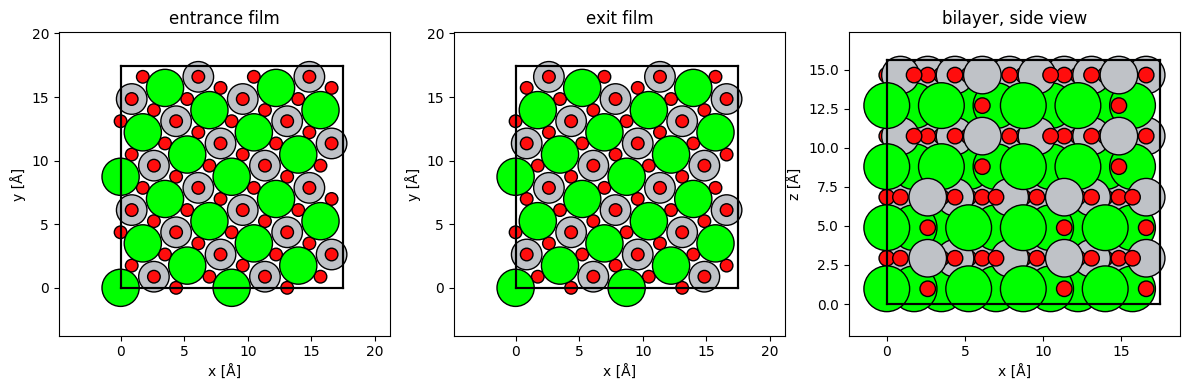

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
abtem.show_atoms(entrance_film, ax=axs[0], title="entrance film")
abtem.show_atoms(exit_film, ax=axs[1], title="exit film")
abtem.show_atoms(bilayer, plane="xz", ax=axs[2], title="bilayer, side view")
fig.tight_layout()

### Imaging conditions

abTEM defines the aberrations at the entrance surface, while the reconstructions reference
them to a plane inside the specimen. A layer at depth $z$ sees the probe with
$C_{10} + z$, so every dataset is simulated with $C_{10} = -100 - z_\text{mid}$ A at the
entrance surface. That puts $C_{10} = -100$ A at the specimen's mid-plane, which is the value
the tutorials start from.

The scan covers exactly one period of the 2 x 2 tiled cell, so every reconstruction is
periodic. The detector is cropped at 60 mrad and binned by two.

In [4]:
energy = 300e3  # eV
semiangle_cutoff = 25  # mrad
C10 = -100  # A, at the mid-plane
focal_spread = 50  # A, rms
bilayer_focal_spread = 20  # A, rms
source_size = 0.25  # A, rms per axis

scan_gpts = (88, 88)
step = side / scan_gpts[0]
bin_factor = 2
wavelength = em.core.utils.utils.electron_wavelength_angstrom(energy)
print(f"step {step:.3f} A, lambda / alpha^2 = {wavelength / (semiangle_cutoff * 1e-3) ** 2:.1f} A")

step 0.198 A, lambda / alpha^2 = 31.5 A


In [5]:
def simulate(atoms, C10_at_mid_plane=C10, tilt=(0.0, 0.0), scan_offset=(0.0, 0.0)):
    potential = abtem.Potential(atoms, sampling=0.05, slice_thickness=lattice_parameter / 2)
    mid_plane = atoms.cell[2, 2] / 2
    C10_entrance = C10_at_mid_plane - mid_plane
    probe = abtem.Probe(
        energy=energy,
        semiangle_cutoff=semiangle_cutoff,
        aberrations={"C10": C10_entrance},
        tilt=tilt,
    )
    probe.grid.match(potential)
    scan = abtem.GridScan(
        scan_offset,
        (scan_offset[0] + side, scan_offset[1] + side),
        gpts=scan_gpts,
        endpoint=False,
    )
    detector = abtem.PixelatedDetector(max_angle=60)
    return probe.scan(potential, scan=scan, detectors=detector).compute()


def binned(measurement):
    array = np.asarray(measurement.array, dtype=np.float32)
    nx, ny = array.shape[-2:]
    array = array[..., : nx - nx % bin_factor, : ny - ny % bin_factor]
    shape = array.shape[:-2] + (nx // bin_factor, bin_factor, ny // bin_factor, bin_factor)
    return array.reshape(shape).sum((-3, -1))


def save(array, path, angular_sampling, **metadata):
    cls = em.core.datastructures.Dataset4dstem if array.ndim == 4 else em.core.datastructures.Dataset
    dataset = cls.from_array(
        array,
        sampling=[1.0] * (array.ndim - 4) + [step, step] + [s * bin_factor for s in angular_sampling],
        units=["index"] * (array.ndim - 4) + ["A", "A", "mrad", "mrad"],
    )
    dataset.metadata.update(
        dict(energy=energy, semiangle_cutoff=semiangle_cutoff, C10=C10, **metadata)
    )
    dataset.save(path, mode="o")
    return dataset

### Ground truth

The phase each film imparts in the projection approximation, $\sigma V_z(\mathbf{r})$,
resampled onto the scan grid. The truth for the bilayer has one image per film, entrance film
first.

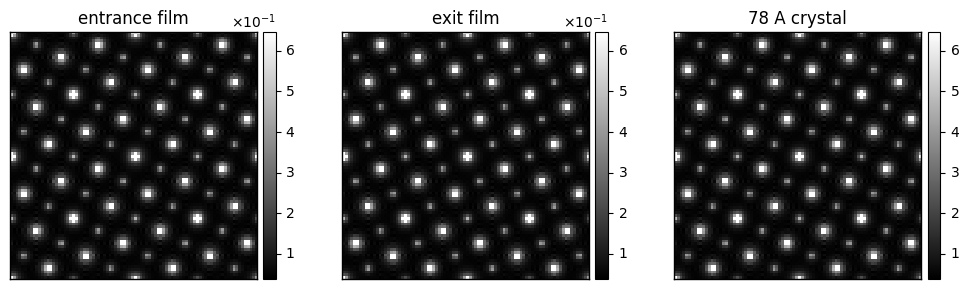

In [6]:
def projected_phase(atoms):
    potential = abtem.Potential(atoms, sampling=0.05, slice_thickness=lattice_parameter / 2)
    image = np.asarray(potential.build(lazy=False).project().array)
    image = image * abtem.core.energy.energy2sigma(energy)
    # band-limited resampling onto the scan grid
    spectrum = np.fft.fft2(image)
    rows = np.fft.fftfreq(scan_gpts[0], 1 / scan_gpts[0]).astype(int) % image.shape[0]
    cols = np.fft.fftfreq(scan_gpts[1], 1 / scan_gpts[1]).astype(int) % image.shape[1]
    resampled = np.fft.ifft2(spectrum[np.ix_(rows, cols)]).real
    return resampled * np.prod(scan_gpts) / image.size


def save_truth(images, path):
    dataset = em.core.datastructures.Dataset.from_array(
        np.stack(images).astype(np.float32),
        sampling=[1.0, step, step],
        units=["index", "A", "A"],
    )
    dataset.save(path, mode="o")
    return dataset


truth_bilayer = save_truth(
    [projected_phase(entrance_film), projected_phase(exit_film)],
    "../../../data/STO-twisted-bilayer_truth.zip",
)
truth_film = save_truth([projected_phase(entrance_film)], "../../../data/STO-film_truth.zip")
truth_thick = save_truth([projected_phase(thick_crystal)], "../../../data/STO-thick_truth.zip")

em.visualization.show_2d(
    [truth_bilayer.array[0], truth_bilayer.array[1], truth_thick.array[0]],
    title=["entrance film", "exit film", "78 A crystal"],
    cbar=True,
);

### The twisted bilayer

In [7]:
measurement = simulate(bilayer)
angular_sampling = measurement.angular_sampling
bilayer_array = binned(measurement)

bilayer_dataset = save(
    bilayer_array,
    "../../../data/STO-twisted-bilayer_300kV_25mrad.zip",
    angular_sampling,
    slice_thickness=2 * lattice_parameter,
)
bilayer_dataset

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

Dataset(shape=(88, 88, 55, 55), dtype=float32, name='4D-STEM dataset')
  sampling: [0.19845103 0.19845103 2.25467675 2.25467675]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

### Tilt series

abTEM's `tilt` tilts the beam against the specimen and leaves the diffraction pattern centred,
which is what a specimen tilt does. A beam tilt of $\theta$ is a specimen tilt of $-\theta$,
the convention the tilt-series reconstruction uses, so the specimen tilts are stored. Four tilts
of 18 mrad (about 1 deg) join the untilted scan, each with a small scan offset standing in for
drift.

abTEM tilts the beam about the entrance surface, so the specimen's mid-plane also moves by
$z_\text{mid}\,\theta$ between tilts, on top of the drift. The tutorial registers the
acquisitions, which absorbs both.

In [8]:
beam_tilts = [(0.0, 0.0), (18.0, 0.0), (-18.0, 0.0), (0.0, 18.0), (0.0, -18.0)]  # mrad
scan_offsets = [(0.0, 0.0), (0.3, -0.2), (-0.25, 0.35), (0.2, 0.25), (-0.35, -0.15)]  # A

tilt_series = [bilayer_array]
for tilt, offset in zip(beam_tilts[1:], scan_offsets[1:]):
    tilt_series.append(binned(simulate(bilayer, tilt=tilt, scan_offset=offset)))

save(
    np.stack(tilt_series),
    "../../../data/STO-twisted-bilayer_300kV_25mrad_tilt-series.zip",
    angular_sampling,
    slice_thickness=2 * lattice_parameter,
    tilt_angles=[[0.0 - tx, 0.0 - ty] for tx, ty in beam_tilts],
    scan_offsets=[list(offset) for offset in scan_offsets],
    tilt_axis_height=bilayer.cell[2, 2] / 2,
)

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

Dataset(shape=(5, 88, 88, 55, 55), dtype=float32, name='5d dataset')
  sampling: [1.         0.19845103 0.19845103 2.25467675 2.25467675]
  units: ['index', 'A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

### Partial coherence

A focal spread is an incoherent average over defocus, here of 11 simulations over
$\pm 3\sigma$ with Gaussian weights. A finite source is an incoherent average over probe
positions. For a Gaussian source that multiplies the scan's Fourier transform by
$\exp(-2\pi^2 \sigma^2 |\mathbf{q}|^2)$, which is applied directly since the scan is
periodic. The bilayer is given a 20 A focal spread alone, and the single film a 50 A focal spread and the
source.

In [9]:
def with_focal_spread(atoms, focal_spread, num_samples=11):
    offsets = np.linspace(-3, 3, num_samples) * focal_spread
    weights = np.exp(-(offsets**2) / (2 * focal_spread**2))
    weights /= weights.sum()
    return sum(
        weight * binned(simulate(atoms, C10_at_mid_plane=C10 + offset))
        for weight, offset in zip(weights, offsets)
    )


def with_source_size(array, source_size):
    q = np.fft.fftfreq(scan_gpts[0], step)
    envelope = np.exp(-2 * np.pi**2 * source_size**2 * (q[:, None] ** 2 + q[None, :] ** 2))
    spectrum = np.fft.fft2(array, axes=(0, 1)) * envelope[:, :, None, None]
    return np.fft.ifft2(spectrum, axes=(0, 1)).real.astype(np.float32)


bilayer_focal = with_focal_spread(bilayer, bilayer_focal_spread)
save(
    bilayer_focal,
    "../../../data/STO-twisted-bilayer_300kV_25mrad_focal-spread.zip",
    angular_sampling,
    slice_thickness=2 * lattice_parameter,
    focal_spread=bilayer_focal_spread,
)

film = entrance_film.copy()
save(binned(simulate(film)), "../../../data/STO-film_300kV_25mrad.zip", angular_sampling)

film_partial = with_source_size(with_focal_spread(film, focal_spread), source_size)
save(
    film_partial,
    "../../../data/STO-film_300kV_25mrad_partial-coherence.zip",
    angular_sampling,
    focal_spread=focal_spread,
    source_size=source_size,
)

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

...

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

Dataset(shape=(88, 88, 55, 55), dtype=float32, name='4D-STEM dataset')
  sampling: [0.19845103 0.19845103 2.25467675 2.25467675]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

### A thick crystal

Twenty unit cells, 78 A, of SrTiO$_3$ in the same orientation as the entrance film. At this
thickness the weak-object approximation fails, which is where Wigner distribution
deconvolution differs from the other kernels.

In [10]:
save(binned(simulate(thick_crystal)), "../../../data/STO-thick_300kV_25mrad.zip", angular_sampling)

tasks:   0%|          | 0/39 [00:00<?, ?it/s]

Dataset(shape=(88, 88, 55, 55), dtype=float32, name='4D-STEM dataset')
  sampling: [0.19845103 0.19845103 2.25467675 2.25467675]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

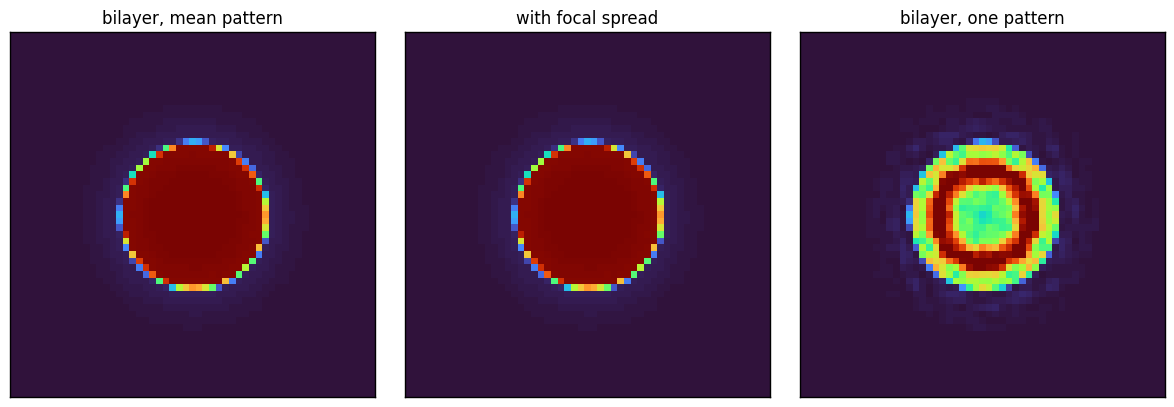

In [11]:
em.visualization.show_2d(
    [
        bilayer_array.mean((0, 1)),
        bilayer_focal.mean((0, 1)),
        bilayer_array[0, 0],
    ],
    title=["bilayer, mean pattern", "with focal spread", "bilayer, one pattern"],
    power=0.5,
    cmap="turbo",
);